## Standard Z-Score Method

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Generate normally distributed data with injected outliers
np.random.seed(42)

# 300 normal exam scores: mean=75, std=8
normal_scores = np.random.normal(loc=75, scale=8, size=300)

# Inject 6 obvious outliers (very low and very high scores)
injected = np.array([35, 40, 42, 110, 115, 118])
all_scores = np.concatenate([normal_scores, injected])

# Build DataFrame
df = pd.DataFrame({"score": all_scores})
print(df.describe())

            score
count  306.000000
mean    74.989162
std      9.430400
min     35.000000
25%     69.401862
50%     75.473756
75%     80.062772
max    118.000000


In [3]:
# Compute Z-Score and flag outliers
k = 3  # Threshold: 2 = sensitive, 2.5 = medium, 3 = strict

# Calculate global mean and std
mean_val = df["score"].mean()
std_val = df["score"].std()

# Compute Z-Score for each point
df["z_score"] = (df["score"] - mean_val) / std_val

# Flag outliers based on absolute Z-Score
df["is_outlier"] = df["z_score"].abs() > k

print(f"Mean: {mean_val:.2f}, Std: {std_val:.2f}")
print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df[df["is_outlier"]].sort_values("score"))

Mean: 74.99, Std: 9.43
Detected outliers: 7
          score   z_score  is_outlier
300   35.000000 -4.240452        True
301   40.000000 -3.710252        True
302   42.000000 -3.498172        True
209  105.821852  3.269500        True
303  110.000000  3.712551        True
304  115.000000  4.242751        True
305  118.000000  4.560871        True


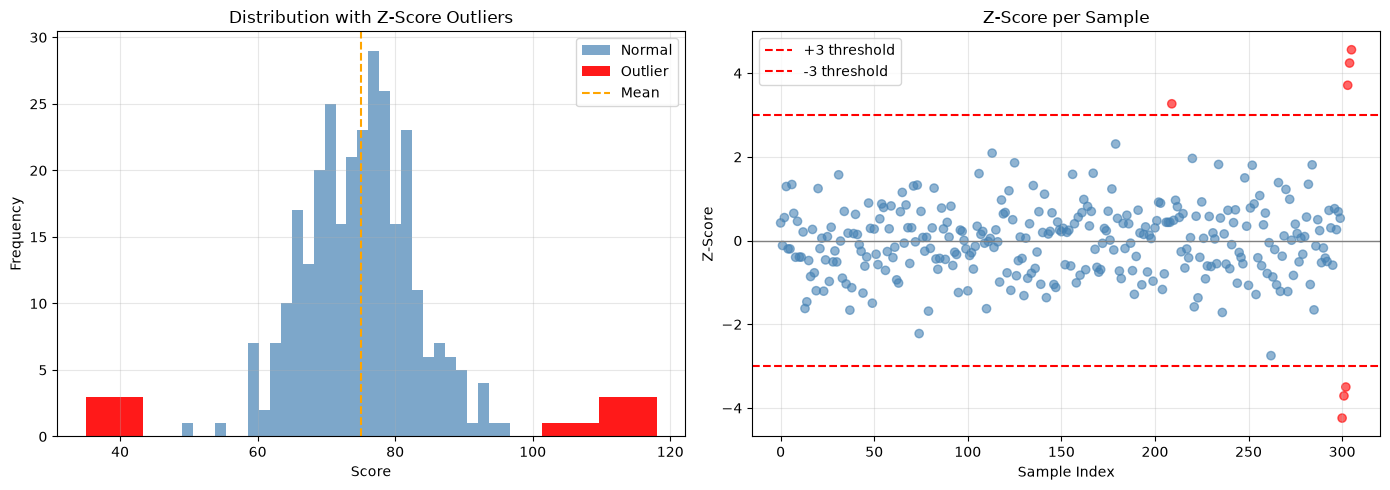

In [4]:
# Visualize distribution and Z-Scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: histogram with outliers highlighted
axes[0].hist(df[~df["is_outlier"]]["score"], bins=30, color="steelblue", alpha=0.7, label="Normal")
axes[0].hist(df[df["is_outlier"]]["score"], bins=10, color="red", alpha=0.9, label="Outlier")
axes[0].axvline(mean_val, color="orange", linestyle="--", label="Mean")
axes[0].set_title("Distribution with Z-Score Outliers")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right plot: Z-Score for each sample index
x_pos = np.arange(len(df))
colors = np.where(df["is_outlier"], "red", "steelblue")
axes[1].scatter(x_pos, df["z_score"], c=colors, alpha=0.6)
axes[1].axhline(k, color="red", linestyle="--", label=f"+{k} threshold")
axes[1].axhline(-k, color="red", linestyle="--", label=f"-{k} threshold")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_title("Z-Score per Sample")
axes[1].set_xlabel("Sample Index")
axes[1].set_ylabel("Z-Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Experiment - compare different thresholds
for threshold in [2.0, 2.5, 3.0]:
    count = ((df["score"] - mean_val).abs() / std_val > threshold).sum()
    print(f"Threshold={threshold}: detected {count} outliers")
# Question: How does lowering the threshold change precision vs recall?

Threshold=2.0: detected 11 outliers
Threshold=2.5: detected 8 outliers
Threshold=3.0: detected 7 outliers
